#**Using transfer learning on Rock Paper Scissors dataset**


Many thanks to the author of this [colab](https://colab.research.google.com/github/trekhleb/machine-learning-experiments/blob/master/experiments/rock_paper_scissors_mobilenet_v2/rock_paper_scissors_mobilenet_v2.ipynb) from which I pinched some code!

# Importing dependencies

In [1]:
%tensorflow_version 2.x
!rm -rf tmp
!rm -rf logs

Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.


In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import os
import math
import random

print('Tensorflow version:', tf.__version__)

Tensorflow version: 2.19.0


# Loading the dataset

Download the Rock-Paper-Scissors dataset from [TensorFlow Datasets](https://github.com/tensorflow/datasets).

In [3]:
(train_data, test_data), dataset_info = tfds.load(
    name="rock_paper_scissors",
    data_dir='tmp',
    with_info=True,
    as_supervised=True,
    split=[tfds.Split.TRAIN, tfds.Split.TEST],
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling tmp/rock_paper_scissors/incomplete.S9W4O2_3.0.0/rock_paper_scissors-train.tfrecord*...:   0%|       …

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling tmp/rock_paper_scissors/incomplete.S9W4O2_3.0.0/rock_paper_scissors-test.tfrecord*...:   0%|        …

Dataset rock_paper_scissors downloaded and prepared to tmp/rock_paper_scissors/3.0.0. Subsequent calls will reuse this data.


In [4]:
dataset_info

tfds.core.DatasetInfo(
    name='rock_paper_scissors',
    full_name='rock_paper_scissors/3.0.0',
    description="""
    Images of hands playing rock, paper, scissor game.
    """,
    homepage='http://laurencemoroney.com/rock-paper-scissors-dataset',
    data_dir='tmp/rock_paper_scissors/3.0.0',
    file_format=tfrecord,
    download_size=219.53 MiB,
    dataset_size=219.23 MiB,
    features=FeaturesDict({
        'image': Image(shape=(300, 300, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=3),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=372, num_shards=1>,
        'train': <SplitInfo num_examples=2520, num_shards=2>,
    },
    citation="""@ONLINE {rps,
    author = "Laurence Moroney",
    title = "Rock, Paper, Scissors Dataset",
    month = "feb",
    year = "2019",
    url = "http://laurencemoroney.com/rock-paper-scissors-datase

## A few example images


In [5]:
# Function to convert label ID to labels string.
get_label_name = dataset_info.features['label'].int2str

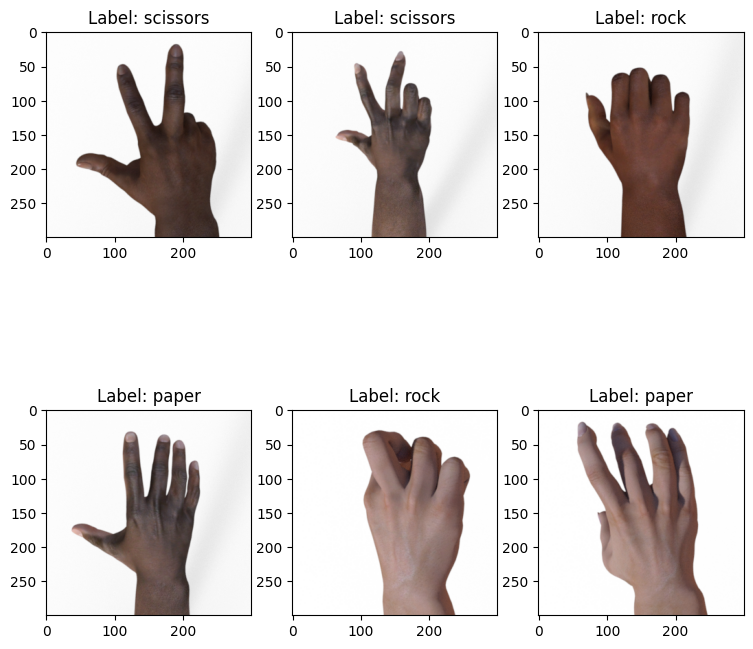

In [6]:
  plt.figure(figsize=(9, 9))
  for i, features in enumerate(train_data.take(6), start=1):
      (image, label) = features
      plt.subplot(2, 3, i)
      label = get_label_name(label.numpy())
      plt.title('Label: %s' % label)
      plt.imshow(image.numpy())

# Data shuffling and batching


In [7]:
BATCH_SIZE = 64
BUFFER_SIZE = 200

train_data = train_data.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

# Prefetch
train_data = train_data.prefetch(tf.data.experimental.AUTOTUNE)

test_data = test_data.batch(BATCH_SIZE).prefetch(tf.data.experimental.AUTOTUNE)

#Creating the model

In [8]:
from tensorflow.keras.applications.mobilenet import MobileNet
from tensorflow.keras.applications.mobilenet import preprocess_input
#from tensorflow.keras.layers.experimental import preprocessing
import tensorflow as tf


input_shape = (224, 224, 3)
original_shape = dataset_info.features["image"].shape
output_size = dataset_info.features["label"].num_classes

# Instantiate MobileNet base model
base_model = MobileNet(
    include_top=False, input_shape=input_shape, weights="imagenet"
)

# Freeze the base model
base_model.trainable = False

# Create augmentation layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.Resizing(*input_shape[:2]),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1)
])

#Ancien
#data_augmentation = tf.keras.Sequential(
 #   [
  #      preprocessing.Resizing(*input_shape[:2]),
   #     preprocessing.RandomRotation(0.1),
    #    preprocessing.RandomZoom(0.1),
     #   preprocessing.RandomTranslation(0.1, 0.1)
    #]
#)

# Create model
inputs = tf.keras.Input(shape=original_shape)    # Input layer
x = data_augmentation(inputs)                    # Augmentation
x = preprocess_input(x)                          # Correct preprocessing function for base model
x = base_model(x, training=False)                # !! Training=False to freeze batchnormalization layers from learning during the fine-tuning phase !!

x = tf.keras.layers.GlobalAveragePooling2D()(x)  # Flatten the results to feed into dense layers
x = tf.keras.layers.Dropout(0.5)(x)              # Dropout layer to fight overfiting

outputs = tf.keras.layers.Dense(                 # Classification layer
    output_size,
    activation="softmax"
)(x)

model = tf.keras.models.Model(inputs, outputs)

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_1.00_224 (Functional) │ (None, 7, 7, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,231,939 (12.33 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

## Compiling the model

In [10]:
rmsprop_optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.0001)

model.compile(
    optimizer=rmsprop_optimizer,
    loss=tf.keras.losses.sparse_categorical_crossentropy,
    metrics=['accuracy']
)

# Training the model

In [11]:
!rm -rf tmp/checkpoints

In [12]:
# checkpoint callback to save the best model (defined by max val accuracy)
checkpoint_filepath = "tmp/.weights.h5"
best_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    checkpoint_filepath,
    save_best_only=True,
    save_weights_only=True,
    monitor='val_accuracy',
    mode='max',
)

In [13]:
training_history = model.fit(
    x=train_data,
    validation_data=test_data,
    epochs=30,
    callbacks=[
        best_checkpoint,
    ],
    verbose=1
)

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 194ms/step - accuracy: 0.2605 - loss: 1.8072 - val_accuracy: 0.4462 - val_loss: 1.0870
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.3383 - loss: 1.5284 - val_accuracy: 0.5753 - val_loss: 0.9234
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.3839 - loss: 1.3183 - val_accuracy: 0.6720 - val_loss: 0.7837
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.4753 - loss: 1.1345 - val_accuracy: 0.8226 - val_loss: 0.6691
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 108ms/step - accuracy: 0.5365 - loss: 0.9959 - val_accuracy: 0.9194 - val_loss: 0.5755
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 106ms/step - accuracy: 0.6400 - loss: 0.7947 - val_accuracy: 0.9274 - val_loss: 0.4997
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.7018 - loss: 0.6690 - val_accuracy: 0.9355 - val_loss: 0.4465
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.7457 - loss: 0.5958 - val_accuracy: 0

In [14]:
model.load_weights(checkpoint_filepath)

## Fine-tuning

In [15]:
# Number of layers in the model
len(base_model.layers)

86

In [16]:
# First, set all the layers to trainable=True
base_model.trainable = True

# Fine-tune from this layer onwards
fine_tune_at = 80

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable =  False

In [17]:
# Set a very low learing_rate
rmsprop_optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.00001)

model.compile(
    optimizer=rmsprop_optimizer,
    loss=tf.keras.losses.sparse_categorical_crossentropy,
    metrics=['accuracy']
)

In [18]:
initial_epochs = training_history.epoch[-1]       # Carry on training from here
fine_tune_epochs = 20                             # Number of fine-tuning epochs

total_epochs =  initial_epochs + fine_tune_epochs # Total number of epochs

training_history_fine = model.fit(
    x=train_data,
    validation_data=test_data,
    epochs=total_epochs,
    initial_epoch=training_history.epoch[-1],
    verbose=1
)

Epoch 30/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - accuracy: 0.8224 - loss: 0.4278 - val_accuracy: 0.9435 - val_loss: 0.2963
Epoch 31/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - accuracy: 0.9177 - loss: 0.2578 - val_accuracy: 0.9543 - val_loss: 0.2230
Epoch 32/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.9225 - loss: 0.2158 - val_accuracy: 0.9516 - val_loss: 0.1846
Epoch 33/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - accuracy: 0.9382 - loss: 0.1663 - val_accuracy: 0.9570 - val_loss: 0.1480
Epoch 34/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - accuracy: 0.9563 - loss: 0.1332 - val_accuracy: 0.9570 - val_loss: 0.1371
Epoch 35/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 115ms/step - accuracy: 0.9686 - loss: 0.1061 - val_accuracy: 0.9597 - val_loss: 0.1190
Epoch 36/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 114ms/step - accuracy: 0.9649 - loss: 0.0954 - val_accuracy: 0.9624 - val_loss: 0.1028
Epoch 37/49
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - accuracy: 0.9826 - loss: 0.0692 - val_accu

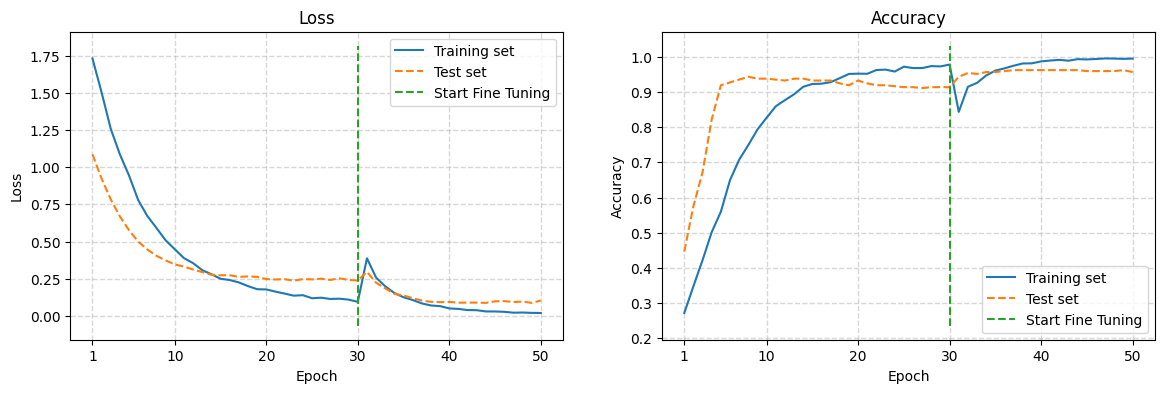

In [19]:
loss = training_history.history['loss'] + training_history_fine.history['loss']
val_loss = training_history.history['val_loss'] + training_history_fine.history['val_loss']

accuracy = training_history.history['accuracy'] + training_history_fine.history['accuracy']
val_accuracy = training_history.history['val_accuracy'] + training_history_fine.history['val_accuracy']

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks([0]+list(range(9, len(loss), 10)), [1]+list(range(10, len(loss)+1, 10)))
plt.plot(loss, label='Training set')
plt.plot(val_loss, label='Test set', linestyle='--')
plt.plot(
[initial_epochs, initial_epochs],
plt.ylim(),
label='Start Fine Tuning',
linestyle='--'
)
plt.legend()
plt.grid(linestyle='--', linewidth=1, alpha=0.5)

plt.subplot(1, 2, 2)
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xticks([0]+list(range(9, len(loss), 10)), [1]+list(range(10, len(loss)+1, 10)))
plt.plot(accuracy, label='Training set')
plt.plot(val_accuracy, label='Test set', linestyle='--')
plt.plot(
[initial_epochs, initial_epochs],
plt.ylim(),
label='Start Fine Tuning',
linestyle='--'
)
plt.legend()
plt.grid(linestyle='--', linewidth=1, alpha=0.5)

plt.show()